# Structural equation modelling (SEM)

**Goal:** Test a theory about *why* students perform well, using latent (unobserved) variables.

**Data:** UCI Student Performance dataset (649 students).

**Model** (semopy)
- Latent variables: **Family background** (mother's and father's education, family relations), **Study behaviour** (study time, few failures, few absences), **Performance** (grades G1, G2, G3)
- Paths: Family background → Study behaviour → Performance, plus a direct Family background → Performance path

**Results**
| Path | Estimate | p-value |
|---|---|---|
| Study behaviour → Performance | 6.84 | < 0.001 ✅ |
| Family background → Study behaviour | 0.09 | < 0.001 ✅ |
| Family background → Performance (direct) | 0.13 | 0.50 ❌ |

**Takeaway:** family background affects grades **indirectly through study behaviour**, not directly. Family relations (`famrel`) did not load significantly on family background, so the measurement model could be refined. SEM is widely used in technology-acceptance research, for example on EV adoption.

---
*Coursework: M.Eng. Engineering & Sustainable Technology Management, AI / Machine Learning courses (2025–2026). Originally run in Google Colab.*

In [ ]:
!pip install semopy

In [ ]:
import pandas as pd
from semopy import Model

In [ ]:
!pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

student_performance = fetch_ucirepo(id=320)

X = student_performance.data.features
y = student_performance.data.targets

df = X.copy()

df = df.join(y)

df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [ ]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [ ]:
import pandas as pd

df = pd.concat([X, y], axis=1)

print(df.columns.tolist())
df.head()

['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [ ]:
df_sem = df[
    [
        "Medu",
        "Fedu",
        "famrel",
        "studytime",
        "failures",
        "absences",
        "G1",
        "G2",
        "G3"
    ]
].copy()

df_sem["failures_r"] = df_sem["failures"].max() - df_sem["failures"]
df_sem["absences_r"] = df_sem["absences"].max() - df_sem["absences"]

In [ ]:
df_sem = df_sem[
    [
        "Medu",
        "Fedu",
        "famrel",
        "studytime",
        "failures_r",
        "absences_r",
        "G1",
        "G2",
        "G3"
    ]
]

df_sem.head()

,Medu,Fedu,famrel,studytime,failures_r,absences_r,G1,G2,G3
0,4,4,4,2,3,28,0,11,11
1,1,1,5,2,3,30,9,11,11
2,1,1,4,2,3,26,12,13,12
3,4,2,3,3,3,32,14,14,14
4,3,3,4,2,3,32,11,13,13


In [ ]:
# Define model
model_desc = """
    FamilyBackground =~ Medu + Fedu + famrel
    StudyBehavior =~ studytime + failures_r + absences_r
    Performance =~ G1 + G2 + G3

    Performance ~ FamilyBackground + StudyBehavior
    StudyBehavior ~ FamilyBackground

"""

# Fit model
model = Model(model_desc)
result = model.fit(df_sem)

In [ ]:
# Step 5: Evaluate the Model
# Inspect parameters and calculate goodness-of-fit metrics.

print("\nParameter Estimates:")
parameters = model.inspect()  # Inspect the parameter estimates
parameters



Parameter Estimates:


,lval,op,rval,Estimate,Std. Err,z-value,p-value
0,Performance,~,FamilyBackground,0.127177,0.187844,0.677034,0.498384
1,Performance,~,StudyBehavior,6.842236,1.575902,4.34179,0.000014
2,StudyBehavior,~,FamilyBackground,0.093024,0.024616,3.778957,0.000157
3,Medu,~,FamilyBackground,1.000000,-,-,-
4,Fedu,~,FamilyBackground,0.828866,0.109271,7.585449,0.0
5,famrel,~,FamilyBackground,0.032697,0.042135,0.776007,0.437745
6,studytime,~,StudyBehavior,1.000000,-,-,-
7,failures_r,~,StudyBehavior,1.180289,0.201927,5.84514,0.0
8,absences_r,~,StudyBehavior,3.198655,0.954744,3.350273,0.000807
9,G1,~,Performance,1.000000,-,-,-


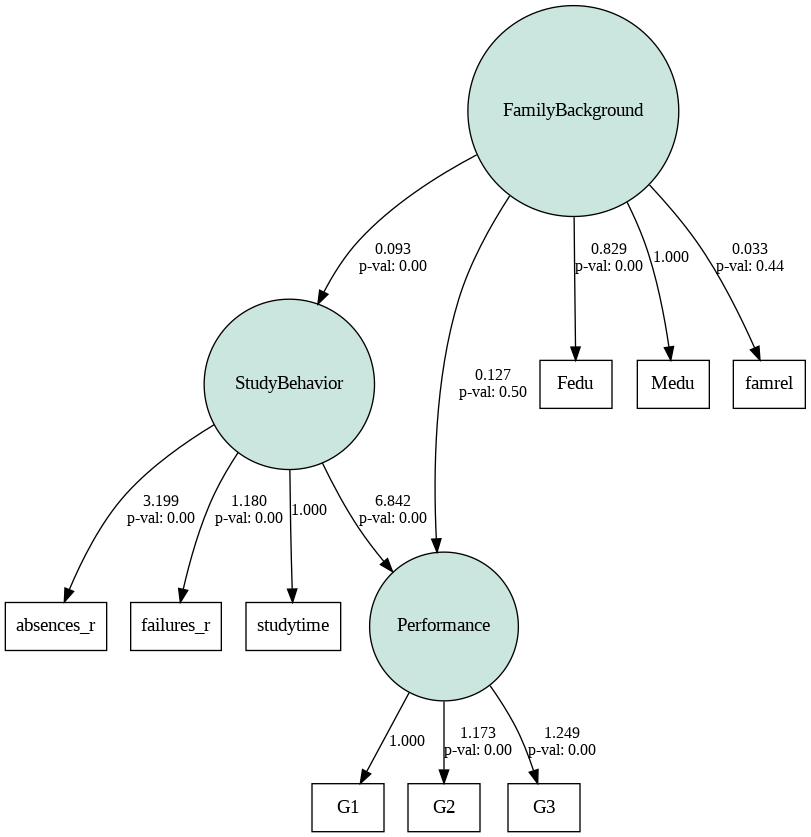

In [ ]:
from semopy import semplot # Import the 'plot' function from semopy

from IPython.display import Image

# Assuming `model` is already defined and fitted

# Step 6: Visualize the SEM Model
# Save the visualization to a file and display it
semplot(model,"model.png")  # Use 'plot' instead of 'plot_sem' to save the diagram
Image(filename="model.png")  # Display the image inline in the notebook